In [1]:
# %% CELL 1 — Setup, imports and loading the data
import sys, subprocess, os, warnings, time
subprocess.run([sys.executable,'-m','pip','install','-q','shap','powerlaw','scikit-posthocs','pyproj','xgboost'],check=False)
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':9})
C=['#1f4e79','#c0504d','#4f9a5b','#e0a030','#7a5c9e','#555555']

CSV='Landslides_Koshi_2024_clean.csv'
if not os.path.exists(CSV):
    from google.colab import files
    print('Please upload Landslides_Koshi_2024_clean.csv'); files.upload()

d_raw=pd.read_csv(CSV)
print('Shape:',d_raw.shape); print('\nFirst rows:'); display(d_raw.head())
print('\nData types:\n',d_raw.dtypes.to_string())
print('\nMissing values per column:\n',d_raw.isna().sum().to_string())
print('\nDuplicate rows:',d_raw.duplicated().sum(),'| Unique IDs:',d_raw.ID.is_unique,'| ID range:',d_raw.ID.min(),'-',d_raw.ID.max())

Please upload Landslides_Koshi_2024_clean.csv


Saving Landslides_Koshi_2024_clean.csv to Landslides_Koshi_2024_clean.csv
Shape: (9210, 8)

First rows:


,Area_,Lat,Long,ID,Elevation,Slope,Aspect,AreaKM2
0,3005.375512,28.017,85.730,1,3745,41,253,0.00301
1,8120.885710,28.016,85.614,2,2813,26,180,0.00812
2,17281.567360,28.017,85.656,3,2371,38,214,0.01728
3,1600.000000,28.012,85.826,4,3220,29,68,0.00160
4,3338.290434,28.011,85.796,5,2592,27,242,0.00334



Data types:
 Area_        float64
Lat          float64
Long         float64
ID             int64
Elevation      int64
Slope          int64
Aspect         int64
AreaKM2      float64

Missing values per column:
 Area_        0
Lat          0
Long         0
ID           0
Elevation    0
Slope        0
Aspect       0
AreaKM2      0

Duplicate rows: 0 | Unique IDs: True | ID range: 1 - 10280


Max |Area_/1e6 - AreaKM2| = 4.999466099997463e-06 -> AreaKM2 is redundant, only Area_ (m2) is used
Records with slope = 0 deg : 2  | slope 1-4 deg (kept): 53
Records after cleaning     : 9208 | duplicated coordinate pairs (kept): 380

Size classes (tertiles): small <= 1,934 m2 | medium <= 3,800 m2 | large > 3,800 m2
size_c
medium    3077
small     3069
large     3062

Log-scale outliers (Tukey): high = 197 low = 0 (retained: genuine large failures)
Skewness of area: raw = 24.0 | log10 = 0.81
Total mapped area = 44.7 km2 | largest 1% of landslides hold 17.8% of area

TABLE I - Descriptive statistics (n = 9208)


,Variable,Min,Q1,Median,Mean,Q3,Max,SD,Skew
0,Area (m2),406.87,1614.48,2689.93,4857.13,4700.0,598593.78,12762.95,24.00
1,Elevation (m),134.00,903.00,1519.50,1857.07,2529.5,5474.00,1225.19,0.80
2,Slope (deg),1.00,22.00,29.00,28.32,35.0,75.00,9.51,-0.22
3,Aspect (deg),1.00,121.00,162.00,165.31,208.0,359.00,65.18,0.25


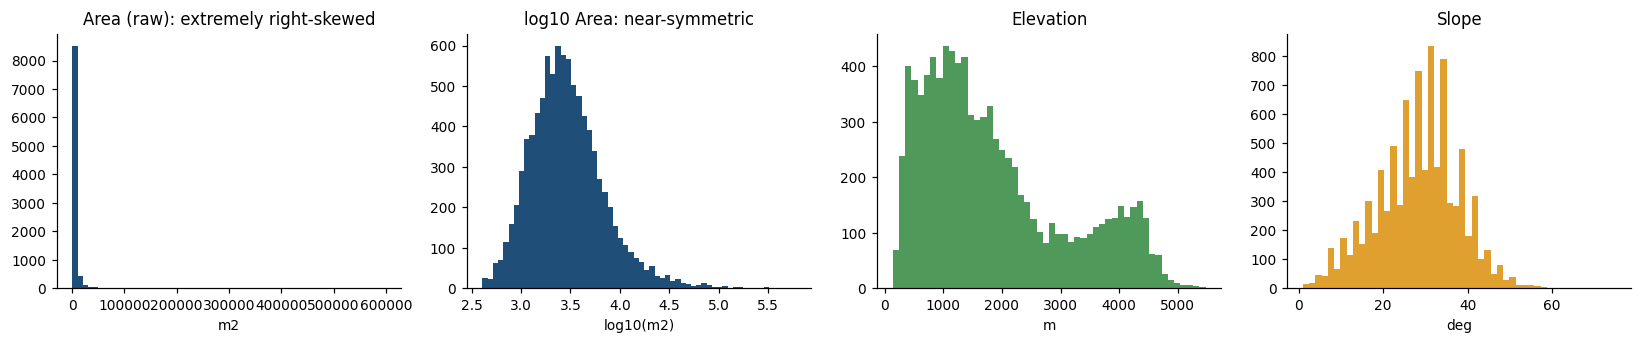

In [2]:
# Data preparation, feature engineering and descriptive statistics
from pyproj import Transformer
print('Max |Area_/1e6 - AreaKM2| =',float((d_raw.Area_/1e6-d_raw.AreaKM2).abs().max()),'-> AreaKM2 is redundant, only Area_ (m2) is used')
print('Records with slope = 0 deg :',int((d_raw.Slope==0).sum()),' | slope 1-4 deg (kept):',int(((d_raw.Slope>0)&(d_raw.Slope<5)).sum()))
d=d_raw[d_raw.Slope>0].reset_index(drop=True)
print('Records after cleaning     :',len(d),'| duplicated coordinate pairs (kept):',int(d.duplicated(['Lat','Long']).sum()))

d['logA']=np.log10(d.Area_)
x,y=Transformer.from_crs(4326,32645,always_xy=True).transform(d.Long.values,d.Lat.values)
d['x']=x/1000; d['y']=y/1000                                   # UTM 45N in km
d['asp_r']=np.deg2rad(d.Aspect); d['sinA']=np.sin(d.asp_r); d['cosA']=np.cos(d.asp_r)
q1,q2=d.Area_.quantile([1/3,2/3]).values
d['size_c']=np.where(d.Area_<=q1,0,np.where(d.Area_<=q2,1,2))
print(f'\nSize classes (tertiles): small <= {q1:,.0f} m2 | medium <= {q2:,.0f} m2 | large > {q2:,.0f} m2')
print(d.size_c.map({0:'small',1:'medium',2:'large'}).value_counts().to_string())

a1,a3=d.logA.quantile([.25,.75]); iqr=a3-a1
print('\nLog-scale outliers (Tukey): high =',int((d.logA>a3+1.5*iqr).sum()),'low =',int((d.logA<a1-1.5*iqr).sum()),'(retained: genuine large failures)')
print('Skewness of area: raw =',round(stats.skew(d.Area_),2),'| log10 =',round(stats.skew(d.logA),2))
print('Total mapped area = %.1f km2 | largest 1%% of landslides hold %.1f%% of area'%(d.AreaKM2.sum(),100*d.Area_.nlargest(int(len(d)*.01)).sum()/d.Area_.sum()))

rows=[]
for c,l in [('Area_','Area (m2)'),('Elevation','Elevation (m)'),('Slope','Slope (deg)'),('Aspect','Aspect (deg)')]:
    v=d[c]; rows.append([l,v.min(),v.quantile(.25),v.median(),v.mean(),v.quantile(.75),v.max(),v.std(),stats.skew(v)])
print('\nTABLE I - Descriptive statistics (n = %d)'%len(d))
display(pd.DataFrame(rows,columns=['Variable','Min','Q1','Median','Mean','Q3','Max','SD','Skew']).round(2))

fig,ax=plt.subplots(1,4,figsize=(15,3.2))
ax[0].hist(d.Area_,bins=60,color=C[0]); ax[0].set_title('Area (raw): extremely right-skewed'); ax[0].set_xlabel('m2')
ax[1].hist(d.logA,bins=60,color=C[0]); ax[1].set_title('log10 Area: near-symmetric'); ax[1].set_xlabel('log10(m2)')
ax[2].hist(d.Elevation,bins=50,color=C[2]); ax[2].set_title('Elevation'); ax[2].set_xlabel('m')
ax[3].hist(d.Slope,bins=50,color=C[3]); ax[3].set_title('Slope'); ax[3].set_xlabel('deg')
plt.tight_layout(); plt.show()

Power law: xmin = 5,097 m2 | alpha = 2.539 +/- 0.034 | KS D = 0.0076 | tail n = 2049 (22.3% of data)
Density rollover (mode) near 2371 m2

TABLE III(b) - Likelihood-ratio tests (R > 0 favours the power law)


,Alternative,LLR (R),p-value
0,lognormal,-0.36,7.166790e-01
1,truncated_power_law,-0.72,3.155287e-01
2,stretched_exponential,1.28,2.003397e-01
3,exponential,6.20,5.668208e-10


TABLE III(a) - Stability of alpha vs lower cut-off


,xmin (m2),alpha,sigma,n tail
0,3000,2.402,0.022,4096
1,4000,2.502,0.028,2890
2,5097,2.539,0.034,2049
3,6000,2.546,0.039,1602
4,8000,2.541,0.048,1024
5,10000,2.550,0.057,731



Bootstrap GOF (200 reps): xmin = 5,211, alpha = 2.542, D = 0.0081, median synthetic D = 0.0129, p = 0.995  (p > 0.1: power law NOT rejected)


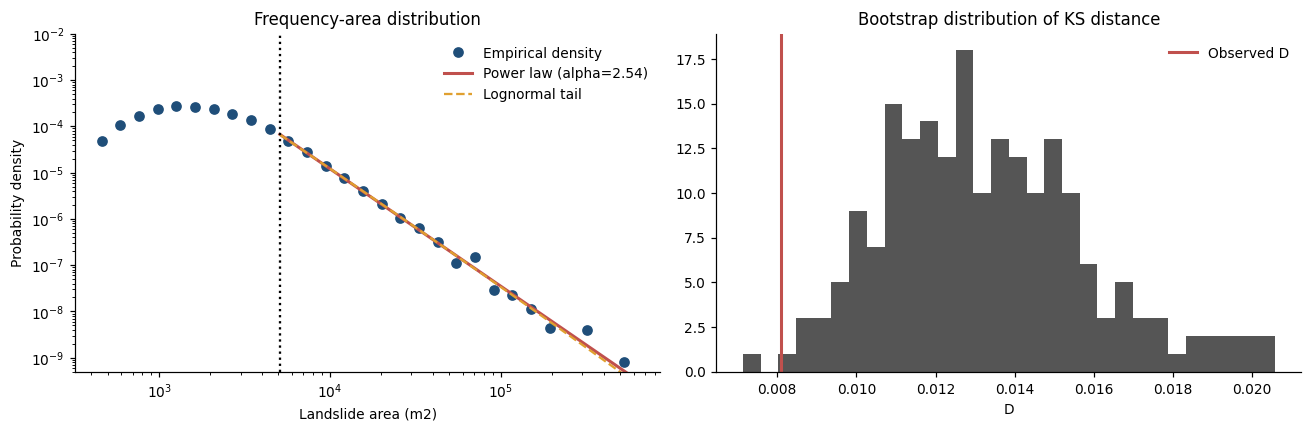

In [3]:
#  Frequency-area distribution (power law, goodness of fit, alternatives)
import powerlaw
a=d.Area_.values
f=powerlaw.Fit(a,verbose=False)
xmin,alpha,sigma,D0=f.xmin,f.alpha,f.sigma,f.D; ntail=int((a>=xmin).sum()); n=len(a)
print(f'Power law: xmin = {xmin:,.0f} m2 | alpha = {alpha:.3f} +/- {sigma:.3f} | KS D = {D0:.4f} | tail n = {ntail} ({100*ntail/n:.1f}% of data)')
h,e=np.histogram(d.logA,bins=60); print('Density rollover (mode) near %.0f m2'%(10**((e[h.argmax()]+e[h.argmax()+1])/2)))
cmp=[]
for alt in ['lognormal','truncated_power_law','stretched_exponential','exponential']:
    R_,p_=f.distribution_compare('power_law',alt,normalized_ratio=True); cmp.append([alt,round(R_,2),p_])
print('\nTABLE III(b) - Likelihood-ratio tests (R > 0 favours the power law)'); display(pd.DataFrame(cmp,columns=['Alternative','LLR (R)','p-value']))
st=[]
for xm in [3000,4000,5097,6000,8000,10000]:
    fx=powerlaw.Fit(a,xmin=xm,verbose=False); st.append([xm,round(fx.power_law.alpha,3),round(fx.power_law.sigma,3),int((a>=xm).sum())])
print('TABLE III(a) - Stability of alpha vs lower cut-off'); display(pd.DataFrame(st,columns=['xmin (m2)','alpha','sigma','n tail']))

# Clauset et al. (2009) semi-parametric bootstrap goodness-of-fit (fast implementation)
rng=np.random.default_rng(42); srt=np.sort(a); cand=np.unique(np.quantile(srt,np.linspace(0.35,0.95,30)))
def fit_pl(x):
    x=np.sort(x); best=(9,None,None)
    for xm in cand:
        t=x[np.searchsorted(x,xm):]
        if len(t)<50: continue
        al=1+len(t)/np.log(t/xm).sum(); cdf=1-(t/xm)**(1-al); k=len(t)
        Dk=max(np.abs(cdf-np.arange(k)/k).max(),np.abs(cdf-np.arange(1,k+1)/k).max())
        if Dk<best[0]: best=(Dk,xm,al)
    return best
Dg,xg,ag=fit_pl(srt); body=srt[srt<xg]; nt=int((srt>=xg).sum()); Ds=[]
for b in range(200):
    nb=rng.binomial(n,nt/n); tail=xg*(1-rng.random(nb))**(-1/(ag-1))
    Ds.append(fit_pl(np.concatenate([rng.choice(body,n-nb),tail]))[0])
print(f'\nBootstrap GOF (200 reps): xmin = {xg:,.0f}, alpha = {ag:.3f}, D = {Dg:.4f}, median synthetic D = {np.median(Ds):.4f}, p = {np.mean(np.array(Ds)>=Dg):.3f}  (p > 0.1: power law NOT rejected)')

from scipy.stats import lognorm
fig,ax=plt.subplots(1,2,figsize=(12,4))
bins=np.logspace(np.log10(a.min()),np.log10(a.max()),30); hh,ee=np.histogram(a,bins=bins,density=True); cc=np.sqrt(ee[1:]*ee[:-1]); m=hh>0
ax[0].loglog(cc[m],hh[m],'o',color=C[0],label='Empirical density')
xs=np.logspace(np.log10(xmin),np.log10(a.max()),50); ax[0].loglog(xs,(alpha-1)/xmin*(xs/xmin)**(-alpha)*(ntail/n),color=C[1],lw=2,label=f'Power law (alpha={alpha:.2f})')
ln=lognorm(s=f.lognormal.sigma,scale=np.exp(f.lognormal.mu)); ax[0].loglog(xs,ln.pdf(xs)/ln.sf(xmin)*(ntail/n),'--',color=C[3],label='Lognormal tail')
ax[0].axvline(xmin,color='k',ls=':'); ax[0].set_ylim(5e-10,1e-2); ax[0].set_xlabel('Landslide area (m2)'); ax[0].set_ylabel('Probability density'); ax[0].set_title('Frequency-area distribution'); ax[0].legend(frameon=False)
ax[1].hist(Ds,bins=30,color=C[5]); ax[1].axvline(Dg,color=C[1],lw=2,label='Observed D'); ax[1].set_title('Bootstrap distribution of KS distance'); ax[1].set_xlabel('D'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

Spearman correlation with log10(area)


,Variable,rho,p-value,95% bootstrap CI
0,Elevation,0.026,0.011,0.005 to 0.047
1,Slope,0.153,4.4e-49,0.135 to 0.173
2,Aspect,0.007,0.5,-0.013 to 0.028
3,Lat,0.064,6.8e-10,0.043 to 0.084
4,Long,-0.012,0.25,-0.031 to 0.008


Elevation vs Latitude rho = 0.71 (collinearity warning)

TABLE IV - Kruskal-Wallis on log10(area) with Dunn-Holm post-hoc


,Factor,Classes,H,p,epsilon^2,Sig. pairs
0,Elevation band,11,47.4,8.0e-07,0.0041,10 / 55
1,Slope class,6,218.7,2.8e-45,0.0232,13 / 15
2,Aspect sector,8,53.6,2.8e-09,0.0051,9 / 28


Median area and counts by slope class:


slope_c,<10,10-19,20-29,30-39,40-49,>=50
n,324.0,1345.0,3054.0,3514.0,887.0,84.0
median_area,2188.0,2361.0,2475.0,2889.0,3438.0,4651.0



Circular aspect statistics: mean direction = 162 deg, R = 0.52, Rayleigh Z = 2533, p = 0.0e+00
Landslides per aspect sector: {'N': 172, 'NE': 468, 'E': 1376, 'SE': 2430, 'S': 2316, 'SW': 1536, 'W': 685, 'NW': 225} | SE+S share = 51.5%


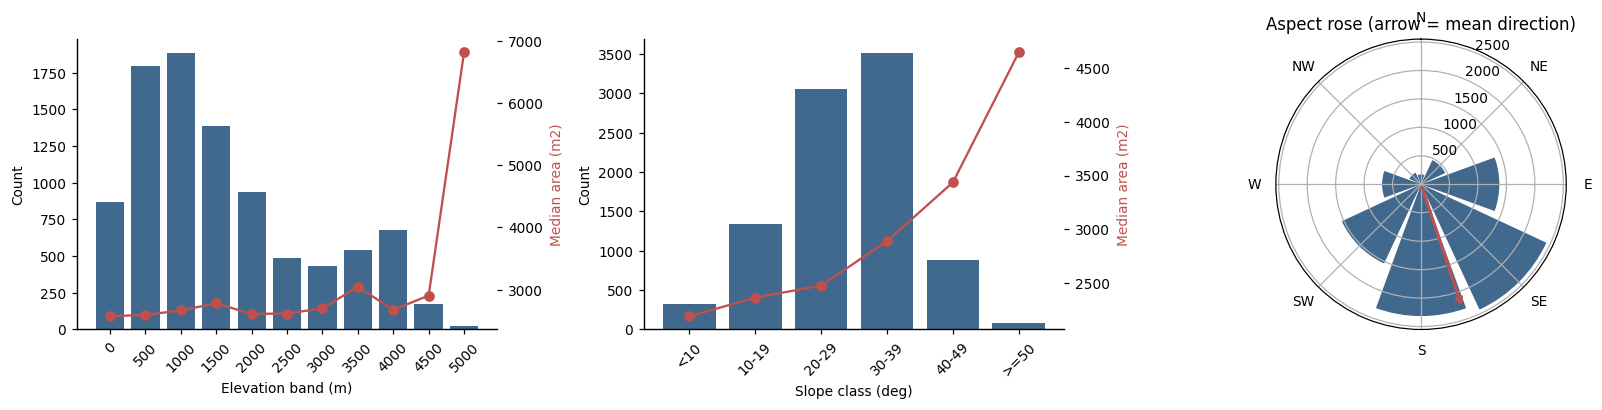

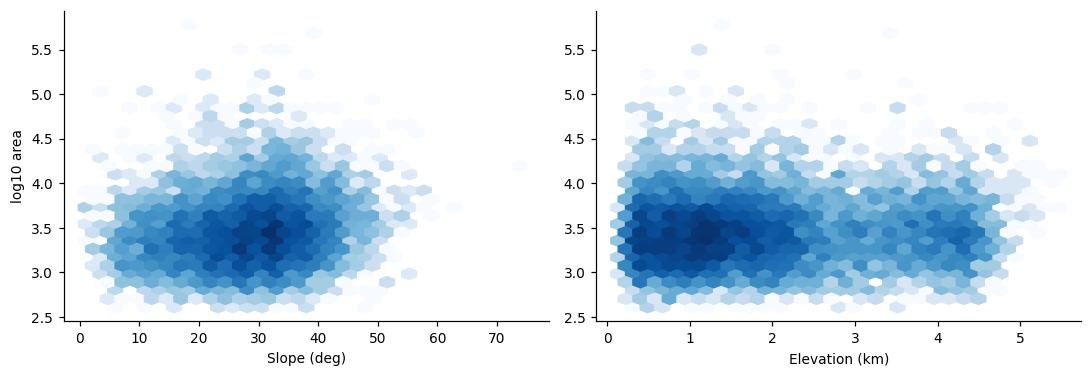

In [4]:
#  — Terrain relationships (Spearman, Kruskal-Wallis, Dunn, circular statistics)
import scikit_posthocs as sp
rng=np.random.default_rng(42)
d['elev_b']=pd.cut(d.Elevation,np.arange(0,6001,500),right=False)
d['slope_c']=pd.cut(d.Slope,[0,10,20,30,40,50,90],right=False,labels=['<10','10-19','20-29','30-39','40-49','>=50'])
sec=['N','NE','E','SE','S','SW','W','NW']
d['asp_s']=pd.cut((d.Aspect+22.5)%360,np.arange(0,361,45),right=False,labels=sec)

sp_rows=[]
for col in ['Elevation','Slope','Aspect','Lat','Long']:
    r,p=stats.spearmanr(d[col],d.logA)
    bs=[stats.spearmanr(d[col].values[i],d.logA.values[i])[0] for i in [rng.integers(0,len(d),len(d)) for _ in range(300)]]
    sp_rows.append([col,round(r,3),f'{p:.2g}',f'{np.percentile(bs,2.5):.3f} to {np.percentile(bs,97.5):.3f}'])
print('Spearman correlation with log10(area)'); display(pd.DataFrame(sp_rows,columns=['Variable','rho','p-value','95% bootstrap CI']))
print('Elevation vs Latitude rho = %.2f (collinearity warning)'%stats.spearmanr(d.Elevation,d.Lat)[0])

kw_rows=[]; tabs={}
for col,name in [('elev_b','Elevation band'),('slope_c','Slope class'),('asp_s','Aspect sector')]:
    g=d.groupby(col,observed=True); keep=[k for k,xx in g if len(xx)>=5]
    H,p=stats.kruskal(*[xx.logA.values for k,xx in g if k in keep]); k=len(keep); eps=(H-k+1)/(len(d)-k)
    sub=d[d[col].isin(keep)].copy(); sub[col]=sub[col].astype(str)
    dn=sp.posthoc_dunn(sub,val_col='logA',group_col=col,p_adjust='holm')
    kw_rows.append([name,k,round(H,1),f'{p:.1e}',round(eps,4),f'{int(np.triu(dn.values<0.05,1).sum())} / {k*(k-1)//2}'])
    tabs[col]=g.agg(n=('logA','size'),median_area=('Area_','median')).round(0)
print('\nTABLE IV - Kruskal-Wallis on log10(area) with Dunn-Holm post-hoc'); display(pd.DataFrame(kw_rows,columns=['Factor','Classes','H','p','epsilon^2','Sig. pairs']))
print('Median area and counts by slope class:'); display(tabs['slope_c'].T)

th=d.asp_r.values; Cm,Sm=np.cos(th).mean(),np.sin(th).mean(); Rb=np.hypot(Cm,Sm); mu=np.rad2deg(np.arctan2(Sm,Cm))%360; nn_=len(th)
Z=nn_*Rb**2; pr=np.exp(np.sqrt(1+4*nn_+4*(nn_**2-(nn_*Rb)**2))-(1+2*nn_))
print(f'\nCircular aspect statistics: mean direction = {mu:.0f} deg, R = {Rb:.2f}, Rayleigh Z = {Z:.0f}, p = {pr:.1e}')
cnt_s=d.asp_s.value_counts().reindex(sec); print('Landslides per aspect sector:',cnt_s.to_dict(),'| SE+S share = %.1f%%'%(100*(cnt_s['SE']+cnt_s['S'])/len(d)))

fig,axs=plt.subplots(1,3,figsize=(15,3.8))
for ax,col,xl in [(axs[0],'elev_b','Elevation band (m)'),(axs[1],'slope_c','Slope class (deg)')]:
    g=d.groupby(col,observed=True); ax.bar(range(len(g)),g.size().values,color=C[0],alpha=.85)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(int(i.left)) if col=='elev_b' else str(i) for i in g.size().index],rotation=45); ax.set_xlabel(xl); ax.set_ylabel('Count')
    a2=ax.twinx(); a2.plot(range(len(g)),g.Area_.median().values,'o-',color=C[1]); a2.set_ylabel('Median area (m2)',color=C[1])
axs[2].remove(); axp=fig.add_subplot(1,3,3,projection='polar'); ang=np.deg2rad(np.arange(0,360,45))
axp.bar(ang,cnt_s.values,width=np.deg2rad(40),color=C[0],alpha=.85); axp.set_theta_zero_location('N'); axp.set_theta_direction(-1); axp.set_xticks(ang); axp.set_xticklabels(sec)
axp.annotate('',xy=(np.deg2rad(mu),cnt_s.max()*.95),xytext=(0,0),arrowprops=dict(arrowstyle='->',color=C[1],lw=2)); axp.set_title('Aspect rose (arrow = mean direction)')
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].hexbin(d.Slope,d.logA,gridsize=30,bins='log',cmap='Blues',mincnt=1); ax[0].set_xlabel('Slope (deg)'); ax[0].set_ylabel('log10 area')
ax[1].hexbin(d.Elevation/1000,d.logA,gridsize=30,bins='log',cmap='Blues',mincnt=1); ax[1].set_xlabel('Elevation (km)')
plt.tight_layout(); plt.show()

Convex hull area = 38,133 km2 | mean NN distance = 0.50 km (expected under CSR 1.02) | Clark-Evans R = 0.49, z = -93.7

TABLE V - Spatial pattern statistics


,Statistic,Value
0,Clark-Evans ratio (z),0.49 (-93.7)
1,L(r)-r at 10 km (CSR envelope),+3.62 (-0.24 to -0.17)
2,"Moran I, counts (360 cells)","0.263 (z=9.6, p=0.001)"
3,"Moran I, mean log area (310 cells)","0.231 (z=7.5, p=0.001)"
4,Gi* hotspot cells (99%),43 (11.9% of occupied cells)
5,Landslides inside hotspot cells,3026 (32.9%)


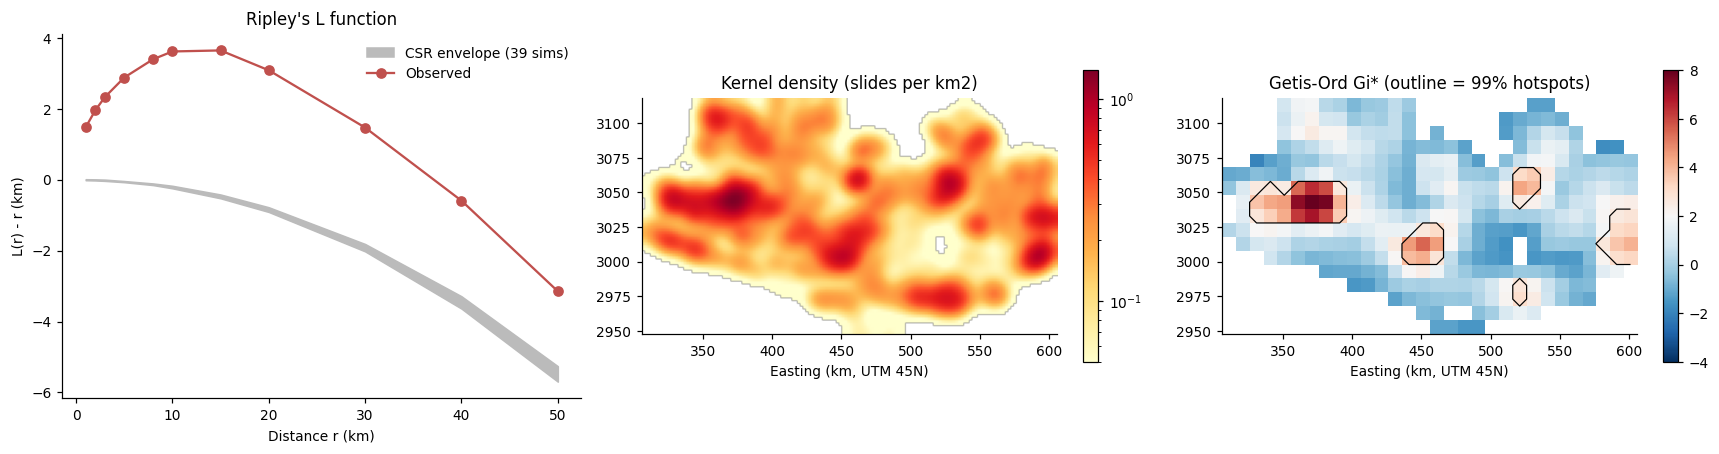

In [5]:
#  Spatial pattern analysis (nearest neighbour, Ripley's K, Moran's I, Getis-Ord Gi*, KDE)
from scipy.spatial import cKDTree, ConvexHull, Delaunay
from scipy import ndimage
rng=np.random.default_rng(42)
P_=d[['x','y']].values; n=len(P_); hull=ConvexHull(P_); Ah=hull.volume
nn=cKDTree(P_).query(P_,k=2)[0][:,1]; nn_exp=0.5/np.sqrt(n/Ah); Rce=nn.mean()/nn_exp; zce=(nn.mean()-nn_exp)/(0.26136/np.sqrt(n*n/Ah))
print(f'Convex hull area = {Ah:,.0f} km2 | mean NN distance = {nn.mean():.2f} km (expected under CSR {nn_exp:.2f}) | Clark-Evans R = {Rce:.2f}, z = {zce:.1f}')

rs=np.array([1,2,3,5,8,10,15,20,30,40,50.])
def Lfun(Q):
    t=cKDTree(Q); c=t.count_neighbors(t,rs)-len(Q); K=Ah*c/(len(Q)*(len(Q)-1)); return np.sqrt(K/np.pi)-rs
Lo=Lfun(P_); dl=Delaunay(P_[hull.vertices]); mn=P_.min(0); mx=P_.max(0)
def csr(m):
    out=[]
    while sum(len(o) for o in out)<m:
        q=rng.uniform(mn,mx,(m*2,2)); out.append(q[dl.find_simplex(q)>=0])
    return np.vstack(out)[:m]
sims=np.array([Lfun(csr(n)) for _ in range(39)])

cs=10; gx=((P_[:,0]-mn[0])//cs).astype(int); gy=((P_[:,1]-mn[1])//cs).astype(int); nx,ny=gx.max()+1,gy.max()+1
cnt=np.zeros((ny,nx)); np.add.at(cnt,(gy,gx),1); ml=np.full((ny,nx),np.nan)
for (i,j),g in d.assign(gy=gy,gx=gx).groupby(['gy','gx']):
    if len(g)>=5: ml[i,j]=g.logA.mean()
def queen(mask):
    idx=-np.ones(mask.shape,int); idx[mask]=np.arange(mask.sum()); W=[[] for _ in range(mask.sum())]
    for i,j in zip(*np.where(mask)):
        for di in (-1,0,1):
            for dj in (-1,0,1):
                if (di or dj) and 0<=i+di<mask.shape[0] and 0<=j+dj<mask.shape[1] and mask[i+di,j+dj]: W[idx[i,j]].append(idx[i+di,j+dj])
    return W
def moran(x,W,perm=999):
    z=x-x.mean()
    def I(z): return sum(z[i]*z[W[i]].mean() for i in range(len(z)) if W[i])/(z**2).sum()
    i0=I(z); sim=np.array([I(rng.permutation(z)) for _ in range(perm)]); return i0,(np.sum(sim>=i0)+1)/(perm+1),(i0-sim.mean())/sim.std()
occ=cnt>0; Ic=moran(cnt[occ],queen(occ)); m5=~np.isnan(ml); Is=moran(ml[m5],queen(m5))
k3=np.ones((3,3)); S_=ndimage.convolve(cnt,k3,mode='constant'); N=cnt.size; xb=cnt.mean(); s=np.sqrt((cnt**2).mean()-xb**2)
wsum=ndimage.convolve(np.ones_like(cnt),k3,mode='constant'); Gz=(S_-xb*wsum)/(s*np.sqrt((N*wsum-wsum**2)/(N-1)))
hot=(Gz>=2.576)&(cnt>0)
h2,xe,ye=np.histogram2d(P_[:,0],P_[:,1],bins=[np.arange(mn[0],mx[0]+2,2),np.arange(mn[1],mx[1]+2,2)]); kde=ndimage.gaussian_filter(h2,3)/4
sub=rng.choice(n,4000,replace=False)   # keeps the random stream identical to the paper run

print('\nTABLE V - Spatial pattern statistics')
display(pd.DataFrame([['Clark-Evans ratio (z)',f'{Rce:.2f} ({zce:.1f})'],
 ['L(r)-r at 10 km (CSR envelope)',f'{Lo[5]:+.2f} ({sims.min(0)[5]:.2f} to {sims.max(0)[5]:.2f})'],
 ['Moran I, counts (%d cells)'%occ.sum(),f'{Ic[0]:.3f} (z={Ic[2]:.1f}, p={Ic[1]:.3f})'],
 ['Moran I, mean log area (%d cells)'%m5.sum(),f'{Is[0]:.3f} (z={Is[2]:.1f}, p={Is[1]:.3f})'],
 ['Gi* hotspot cells (99%)',f'{hot.sum()} ({100*hot.sum()/occ.sum():.1f}% of occupied cells)'],
 ['Landslides inside hotspot cells',f'{int(cnt[hot].sum())} ({100*cnt[hot].sum()/n:.1f}%)']],columns=['Statistic','Value']))

fig,ax=plt.subplots(1,3,figsize=(16,4.2))
ax[0].fill_between(rs,sims.min(0),sims.max(0),color='#bbbbbb',label='CSR envelope (39 sims)'); ax[0].plot(rs,Lo,'o-',color=C[1],label='Observed')
ax[0].set_xlabel('Distance r (km)'); ax[0].set_ylabel('L(r) - r (km)'); ax[0].set_title("Ripley's L function"); ax[0].legend(frameon=False)
im=ax[1].imshow(np.ma.masked_less(kde.T,0.02),origin='lower',extent=[xe[0],xe[-1],ye[0],ye[-1]],cmap='YlOrRd',norm=matplotlib.colors.LogNorm(vmin=0.05,vmax=kde.max())); ax[1].set_title('Kernel density (slides per km2)'); plt.colorbar(im,ax=ax[1],shrink=.8)
ext=[mn[0],mn[0]+nx*cs,mn[1],mn[1]+ny*cs]; im2=ax[2].imshow(np.ma.masked_where(cnt==0,Gz),origin='lower',extent=ext,cmap='RdBu_r',vmin=-4,vmax=8)
ax[2].contour(np.linspace(ext[0]+cs/2,ext[1]-cs/2,nx),np.linspace(ext[2]+cs/2,ext[3]-cs/2,ny),hot,levels=[.5],colors='k',linewidths=.8); ax[2].set_title('Getis-Ord Gi* (outline = 99% hotspots)'); plt.colorbar(im2,ax=ax[2],shrink=.8)
for a_ in ax[1:]: a_.set_xlabel('Easting (km, UTM 45N)')
plt.tight_layout(); plt.show()

DBSCAN parameter scan (silhouette / Davies-Bouldin on clustered points only)


,eps (km),MinPts,clusters,noise share,silhouette,Davies-Bouldin
0,2,20,52,0.654,0.618,0.434
1,2,40,14,0.892,0.717,0.377
2,2,80,0,1.000,NaN,NaN
3,3,20,60,0.377,0.378,0.524
4,3,40,23,0.691,0.625,0.428
5,3,80,4,0.958,0.813,0.365
6,5,20,24,0.088,0.166,0.783
7,5,40,24,0.330,0.428,0.534
8,5,80,12,0.667,0.663,0.361
9,8,20,2,0.011,-0.009,0.929



FINAL DBSCAN (eps=5 km, MinPts=40): 24 clusters, noise = 33.0%, silhouette = 0.43, Davies-Bouldin = 0.53
Median area clustered vs noise: 2693 vs 2676 m2 (Mann-Whitney p = 0.93); size differs among clusters: KW H = 191.9, p = 1.3e-28
Largest clusters:


,n,lat,lon,median_area
db,,,,
3,1638,27.50,85.62,2637.66
11,790,27.23,86.53,2648.05
12,497,26.89,87.20,2994.14
18,447,27.61,87.27,3099.22
23,375,27.17,87.93,1913.44



K-means model selection (terrain features)


,k,inertia,silhouette,Davies-Bouldin
0,2,28739.0,0.237,1.705
1,3,23060.0,0.259,1.426
2,4,19260.0,0.253,1.273
3,5,16633.0,0.249,1.186
4,6,14671.0,0.249,1.101
5,7,13399.0,0.256,1.153
6,8,12406.0,0.253,1.185
7,9,11523.0,0.242,1.189
8,10,10732.0,0.253,1.114


TABLE VI - K-means clusters (k = 3)


,n,median_elev,median_slope,mean_sin,mean_cos,median_area,pct_large
km,,,,,,,
0,2443,1392.0,26.0,0.66,0.15,2668.66,33.61
1,2106,3758.5,33.0,0.11,-0.67,2830.24,35.99
2,4659,1148.0,29.0,-0.07,-0.76,2629.15,31.83


KW on log area across K-means clusters: H = 9.8, p = 0.0076, epsilon^2 = 0.0008 | ARI vs size classes = 0.0004, NMI = 0.0006


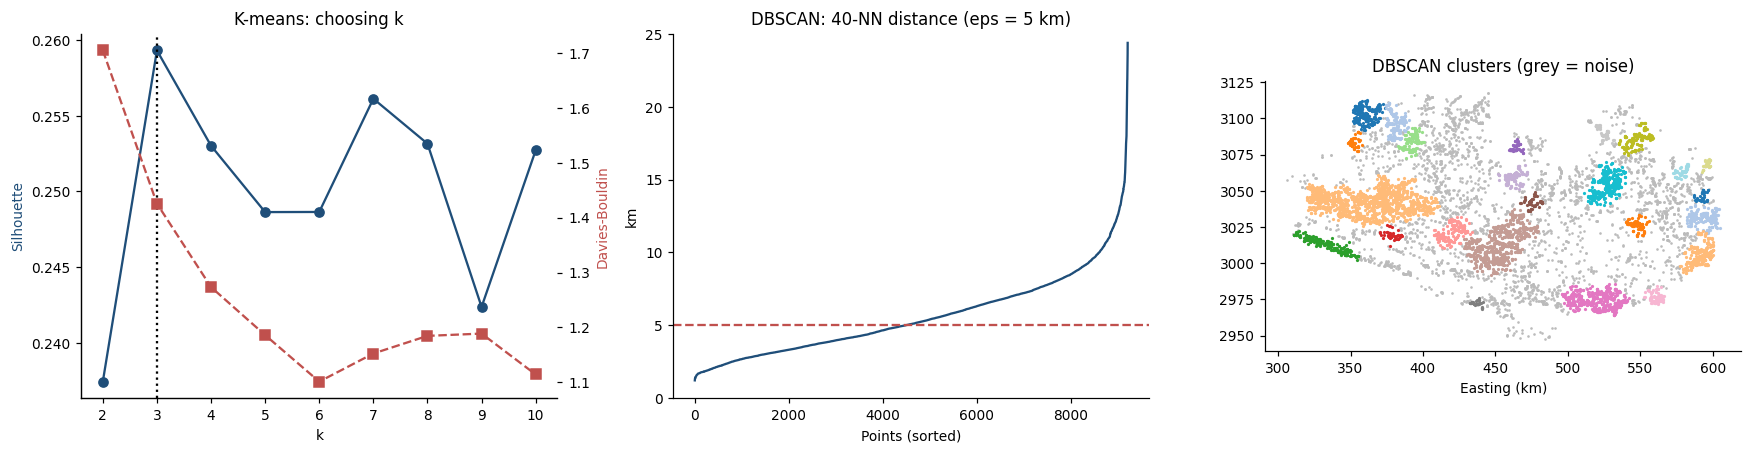

In [6]:
#  Clustering: DBSCAN (space) and K-means (terrain)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
res=[]
for eps in [2,3,5,8]:
    for ms in [20,40,80]:
        lab=DBSCAN(eps=eps,min_samples=ms).fit_predict(P_); nc=len(set(lab))-(1 if -1 in lab else 0); sil=dbi=np.nan
        if nc>=2:
            idx=np.where(lab!=-1)[0]; ss=rng.choice(idx,min(4000,len(idx)),replace=False); sil=silhouette_score(P_[ss],lab[ss]); dbi=davies_bouldin_score(P_[idx],lab[idx])
        res.append([eps,ms,nc,round((lab==-1).mean(),3),round(sil,3),round(dbi,3)])
print('DBSCAN parameter scan (silhouette / Davies-Bouldin on clustered points only)'); display(pd.DataFrame(res,columns=['eps (km)','MinPts','clusters','noise share','silhouette','Davies-Bouldin']))

rng=np.random.default_rng(42)
lab=DBSCAN(eps=5,min_samples=40).fit_predict(P_); d['db']=lab; mk=lab>=0
ss=rng.choice(np.where(mk)[0],4000,replace=False)
big=[c for c,g in d[mk].groupby('db') if len(g)>=30]; Hk,pk=stats.kruskal(*[d.logA[d.db==c] for c in big])
print(f'\nFINAL DBSCAN (eps=5 km, MinPts=40): {len(set(lab))-1} clusters, noise = {100*(lab==-1).mean():.1f}%, silhouette = {silhouette_score(P_[ss],lab[ss]):.2f}, Davies-Bouldin = {davies_bouldin_score(P_[mk],lab[mk]):.2f}')
print(f'Median area clustered vs noise: {d.Area_[mk].median():.0f} vs {d.Area_[~mk].median():.0f} m2 (Mann-Whitney p = {stats.mannwhitneyu(d.Area_[mk],d.Area_[~mk]).pvalue:.2f}); size differs among clusters: KW H = {Hk:.1f}, p = {pk:.1e}')
print('Largest clusters:'); display(d[mk].groupby('db').agg(n=('x','size'),lat=('Lat','mean'),lon=('Long','mean'),median_area=('Area_','median')).sort_values('n',ascending=False).head(5).round(2))

X=StandardScaler().fit_transform(d[['Elevation','Slope','sinA','cosA']]); sub=rng.choice(len(d),5000,replace=False); ks=list(range(2,11)); ine=[]; sil=[]; dbi=[]
for k in ks:
    km=KMeans(k,n_init=10,random_state=42).fit(X); ine.append(km.inertia_); sil.append(silhouette_score(X[sub],km.labels_[sub])); dbi.append(davies_bouldin_score(X,km.labels_))
print('\nK-means model selection (terrain features)'); display(pd.DataFrame({'k':ks,'inertia':np.round(ine),'silhouette':np.round(sil,3),'Davies-Bouldin':np.round(dbi,3)}))
kbest=ks[int(np.argmax(sil))]; km=KMeans(kbest,n_init=20,random_state=42).fit(X); d['km']=km.labels_
prof=d.groupby('km').agg(n=('x','size'),median_elev=('Elevation','median'),median_slope=('Slope','median'),mean_sin=('sinA','mean'),mean_cos=('cosA','mean'),median_area=('Area_','median'),pct_large=('size_c',lambda s_:100*(s_==2).mean())).round(2)
print(f'TABLE VI - K-means clusters (k = {kbest})'); display(prof)
Hm,pm=stats.kruskal(*[g.logA.values for _,g in d.groupby('km')])
print(f'KW on log area across K-means clusters: H = {Hm:.1f}, p = {pm:.4f}, epsilon^2 = {(Hm-kbest+1)/(len(d)-kbest):.4f} | ARI vs size classes = {adjusted_rand_score(d.size_c,d.km):.4f}, NMI = {normalized_mutual_info_score(d.size_c,d.km):.4f}')

fig,ax=plt.subplots(1,3,figsize=(16,4.2))
ax[0].plot(ks,sil,'o-',color=C[0]); ax[0].set_ylabel('Silhouette',color=C[0]); ax[0].set_xlabel('k'); ax[0].axvline(kbest,color='k',ls=':'); a2=ax[0].twinx(); a2.plot(ks,dbi,'s--',color=C[1]); a2.set_ylabel('Davies-Bouldin',color=C[1]); ax[0].set_title('K-means: choosing k')
ax[1].plot(np.sort(cKDTree(P_).query(P_,k=40)[0][:,-1]),color=C[0]); ax[1].axhline(5,color=C[1],ls='--'); ax[1].set_ylim(0,25); ax[1].set_title('DBSCAN: 40-NN distance (eps = 5 km)'); ax[1].set_xlabel('Points (sorted)'); ax[1].set_ylabel('km')
ax[2].scatter(P_[lab<0,0],P_[lab<0,1],s=.5,c='#bbbbbb'); cm=plt.cm.tab20(np.linspace(0,1,20))
for c in sorted(set(lab)-{-1}): ax[2].scatter(P_[lab==c,0],P_[lab==c,1],s=1.2,color=cm[c%20])
ax[2].set_aspect('equal'); ax[2].set_title('DBSCAN clusters (grey = noise)'); ax[2].set_xlabel('Easting (km)')
plt.tight_layout(); plt.show()

Spatial blocks (25 km): 72 | train = 7308 | test = 1900 (20.6%) | test class shares = [0.332 0.341 0.328]
Majority-class baseline: accuracy = 0.332, macro-F1 = 0.166

Running grid search with spatial GroupKFold (takes a few minutes)...
  Logistic Regression done (2s)
  Random Forest done (65s)
  XGBoost done (77s)

TABLE VII (E1) - Spatial hold-out results


,Model,Selected hyper-parameters,CV macro-F1,Test acc.,95% CI,Macro-F1,Bal. acc.,AUC (OvR),p vs majority
0,Logistic Regression,{'logisticregression__C': 0.01},0.354 +/- 0.011,0.385,0.362-0.407,0.377,0.386,0.550,3.1e-05
1,Random Forest,"{'max_depth': 10, 'min_samples_leaf': 10}",0.378 +/- 0.018,0.380,0.357-0.402,0.377,0.380,0.545,1.7e-04
2,XGBoost,"{'max_depth': 3, 'min_child_weight': 20}",0.376 +/- 0.018,0.375,0.352-0.397,0.372,0.374,0.550,9.6e-04


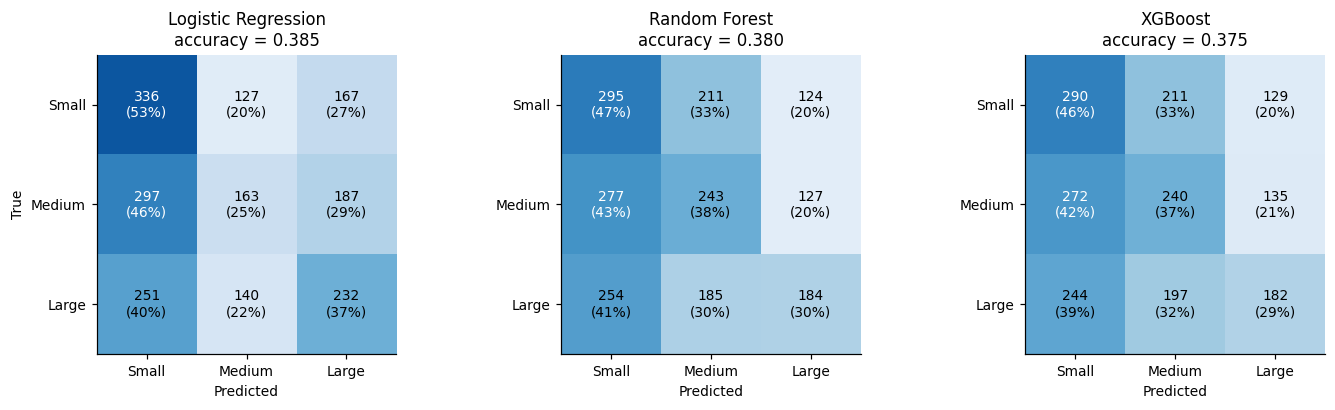

In [7]:
#  — Classification, experiment E1: spatial block validation (terrain + coordinates)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedKFold, GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score,f1_score,balanced_accuracy_score,confusion_matrix,roc_auc_score,mean_squared_error,r2_score,mean_absolute_error
from xgboost import XGBClassifier, XGBRegressor
T0=time.time()
F_all=['Elevation','Slope','sinA','cosA','Lat','Long']; F_ter=['Elevation','Slope','sinA','cosA']
y=d.size_c.values; yr=d.logA.values
groups=(((d.x-d.x.min())//25).astype(int)*100+((d.y-d.y.min())//25).astype(int)).values
tr,te=next(GroupShuffleSplit(1,test_size=0.2,random_state=42).split(d,y,groups))
rtr,rte=train_test_split(np.arange(len(d)),test_size=0.2,random_state=42,stratify=y)
print(f'Spatial blocks (25 km): {len(set(groups))} | train = {len(tr)} | test = {len(te)} ({100*len(te)/len(d):.1f}%) | test class shares = {np.round(np.bincount(y[te])/len(te),3)}')
maj=np.bincount(y[tr]).argmax(); base_acc=(y[te]==maj).mean(); base_f1=f1_score(y[te],np.full(len(te),maj),average='macro')
print(f'Majority-class baseline: accuracy = {base_acc:.3f}, macro-F1 = {base_f1:.3f}')
def models():
    return {'Logistic Regression':(make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),{'logisticregression__C':[0.01,0.1,1,10]}),
     'Random Forest':(RandomForestClassifier(n_estimators=150,random_state=42,n_jobs=1),{'max_depth':[6,10,None],'min_samples_leaf':[10,40]}),
     'XGBoost':(XGBClassifier(n_estimators=150,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,random_state=42,n_jobs=1,eval_metric='mlogloss'),{'max_depth':[2,3,5],'min_child_weight':[5,20]})}
def run(feat,split='spatial'):
    X=d[feat].values; out={}; itr,ite=(tr,te) if split=='spatial' else (rtr,rte)
    for name,(m,grid) in models().items():
        cv=GroupKFold(5).split(X[itr],y[itr],groups[itr]) if split=='spatial' else StratifiedKFold(5,shuffle=True,random_state=42)
        gs=GridSearchCV(m,grid,cv=cv,scoring='f1_macro',n_jobs=1).fit(X[itr],y[itr]); b=gs.best_estimator_; p=b.predict(X[ite]); pr=b.predict_proba(X[ite])
        bs=[accuracy_score(y[ite][i],p[i]) for i in [np.random.default_rng(k).integers(0,len(ite),len(ite)) for k in range(500)]]
        out[name]=dict(best=gs.best_params_,cv_f1=gs.best_score_,cv_sd=gs.cv_results_['std_test_score'][gs.best_index_],acc=accuracy_score(y[ite],p),ci=(np.percentile(bs,2.5),np.percentile(bs,97.5)),
            f1=f1_score(y[ite],p,average='macro'),bacc=balanced_accuracy_score(y[ite],p),auc=roc_auc_score(y[ite],pr,multi_class='ovr'),cm=confusion_matrix(y[ite],p),model=b,
            binom=stats.binomtest(int((p==y[ite]).sum()),len(ite),max(np.bincount(y[ite]))/len(ite),alternative='greater').pvalue)
        print(f'  {name} done ({time.time()-T0:.0f}s)')
    return out
print('\nRunning grid search with spatial GroupKFold (takes a few minutes)...'); E1=run(F_all)
tab=pd.DataFrame([[k,str(v['best']),f"{v['cv_f1']:.3f} +/- {v['cv_sd']:.3f}",round(v['acc'],3),f"{v['ci'][0]:.3f}-{v['ci'][1]:.3f}",round(v['f1'],3),round(v['bacc'],3),round(v['auc'],3),f"{v['binom']:.1e}"] for k,v in E1.items()],
  columns=['Model','Selected hyper-parameters','CV macro-F1','Test acc.','95% CI','Macro-F1','Bal. acc.','AUC (OvR)','p vs majority'])
print('\nTABLE VII (E1) - Spatial hold-out results'); display(tab)
fig,axs=plt.subplots(1,3,figsize=(13,3.8))
for ax,(k,v) in zip(axs,E1.items()):
    cm_=v['cm']; cn=cm_/cm_.sum(1,keepdims=True); ax.imshow(cn,cmap='Blues',vmin=.15,vmax=.6)
    for i in range(3):
        for j in range(3): ax.text(j,i,f'{cm_[i,j]}\n({cn[i,j]*100:.0f}%)',ha='center',va='center',color='white' if cn[i,j]>.42 else 'black')
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(['Small','Medium','Large']); ax.set_yticklabels(['Small','Medium','Large']); ax.set_xlabel('Predicted'); ax.set_title(f'{k}\naccuracy = {v["acc"]:.3f}')
axs[0].set_ylabel('True'); plt.tight_layout(); plt.show()

E2: terrain only (no coordinates), spatial validation
  Logistic Regression done (108s)
  Random Forest done (157s)
  XGBoost done (167s)
E3: terrain + coordinates, RANDOM split
  Logistic Regression done (168s)
  Random Forest done (221s)
  XGBoost done (233s)

TABLE VII - Classification performance, all experiments


,Experiment,Model,CV macro-F1,Test acc.,Test macro-F1,AUC
0,Baseline,Majority class,-,0.332,0.166,0.500
1,E1 spatial + coords,Logistic Regression,0.354,0.385,0.377,0.550
2,E1 spatial + coords,Random Forest,0.378,0.380,0.377,0.545
3,E1 spatial + coords,XGBoost,0.376,0.375,0.372,0.550
4,E2 spatial terrain only,Logistic Regression,0.369,0.378,0.360,0.552
5,E2 spatial terrain only,Random Forest,0.377,0.372,0.368,0.546
6,E2 spatial terrain only,XGBoost,0.373,0.373,0.370,0.546
7,E3 random + coords,Logistic Regression,0.375,0.376,0.366,0.559
8,E3 random + coords,Random Forest,0.398,0.390,0.386,0.574
9,E3 random + coords,XGBoost,0.401,0.400,0.399,0.580


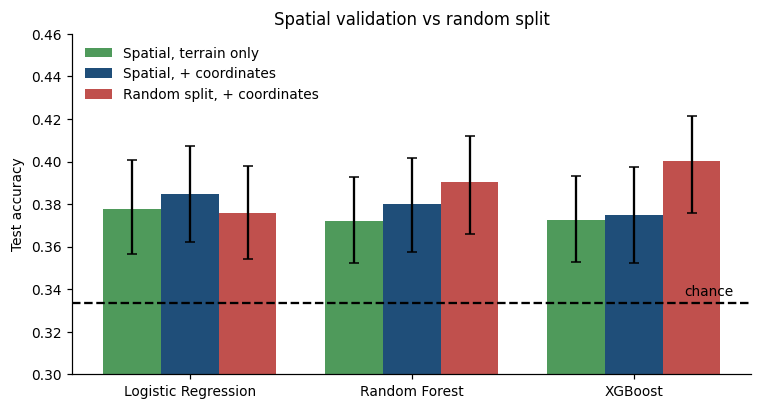

TABLE VIII - Regression of log10(area), spatial block validation


,Model,CV R2,Test RMSE,Test MAE,Test R2
0,Mean baseline,-,0.361,-,-0.000
1,Linear,0.016,0.359,0.276,0.012
2,Random Forest,0.029,0.356,0.276,0.024
3,XGBoost,0.03,0.358,0.276,0.017


In [8]:
#  Ablation (E2 terrain only, E3 random split) and regression check
print('E2: terrain only (no coordinates), spatial validation'); E2=run(F_ter)
print('E3: terrain + coordinates, RANDOM split'); E3=run(F_all,'random')
rows=[['Baseline','Majority class','-',round(base_acc,3),round(base_f1,3),0.5]]
for nm,E in [('E1 spatial + coords',E1),('E2 spatial terrain only',E2),('E3 random + coords',E3)]:
    for k,v in E.items(): rows.append([nm,k,round(v['cv_f1'],3),round(v['acc'],3),round(v['f1'],3),round(v['auc'],3)])
print('\nTABLE VII - Classification performance, all experiments'); display(pd.DataFrame(rows,columns=['Experiment','Model','CV macro-F1','Test acc.','Test macro-F1','AUC']))

fig,ax=plt.subplots(figsize=(7,3.8)); w=.26; xx=np.arange(3); names=list(E1.keys())
for k_,(E,l,c) in enumerate([(E2,'Spatial, terrain only',C[2]),(E1,'Spatial, + coordinates',C[0]),(E3,'Random split, + coordinates',C[1])]):
    v=[E[m]['acc'] for m in names]; err=[[E[m]['acc']-E[m]['ci'][0] for m in names],[E[m]['ci'][1]-E[m]['acc'] for m in names]]
    ax.bar(xx+(k_-1)*w,v,w,yerr=err,color=c,label=l,capsize=3)
ax.axhline(1/3,color='k',ls='--'); ax.text(2.45,.337,'chance',ha='right'); ax.set_xticks(xx); ax.set_xticklabels(names); ax.set_ylim(.30,.46); ax.set_ylabel('Test accuracy'); ax.legend(frameon=False,loc='upper left'); ax.set_title('Spatial validation vs random split')
plt.tight_layout(); plt.show()

X=d[F_all].values; gkf=GroupKFold(5); reg=[]
regs={'Linear':LinearRegression(),'Random Forest':RandomForestRegressor(n_estimators=300,min_samples_leaf=20,max_depth=8,random_state=42,n_jobs=1),'XGBoost':XGBRegressor(n_estimators=150,learning_rate=0.05,max_depth=3,min_child_weight=20,subsample=0.8,random_state=42,n_jobs=1)}
mean_pred=np.full(len(te),yr[tr].mean()); reg.append(['Mean baseline','-',round(np.sqrt(mean_squared_error(yr[te],mean_pred)),3),'-',round(r2_score(yr[te],mean_pred),3)])
for nm,m in regs.items():
    cvr=[r2_score(yr[tr][b],m.fit(X[tr][a_],yr[tr][a_]).predict(X[tr][b])) for a_,b in gkf.split(X[tr],yr[tr],groups[tr])]
    m.fit(X[tr],yr[tr]); p=m.predict(X[te]); reg.append([nm,round(np.mean(cvr),3),round(np.sqrt(mean_squared_error(yr[te],p)),3),round(mean_absolute_error(yr[te],p),3),round(r2_score(yr[te],p),3)])
print('TABLE VIII - Regression of log10(area), spatial block validation'); display(pd.DataFrame(reg,columns=['Model','CV R2','Test RMSE','Test MAE','Test R2']))

TABLE - Feature importance


,Feature,Mean |SHAP| (XGBoost),Permutation dF1 (RF),+/- SD
1,Slope,0.1077,0.0331,0.0101
3,cosA,0.0470,0.0197,0.0064
4,Lat,0.0461,0.0154,0.0078
0,Elevation,0.0379,0.0012,0.0057
5,Long,0.0361,0.0119,0.0049
2,sinA,0.0340,-0.0016,0.0075



Logistic Regression standardised coefficients (per class):


,small,medium,large
Elevation,0.052,-0.004,-0.048
Slope,-0.172,-0.024,0.197
sinA,0.014,0.039,-0.054
cosA,-0.067,-0.041,0.108
Lat,-0.085,0.001,0.084
Long,0.010,-0.023,0.013


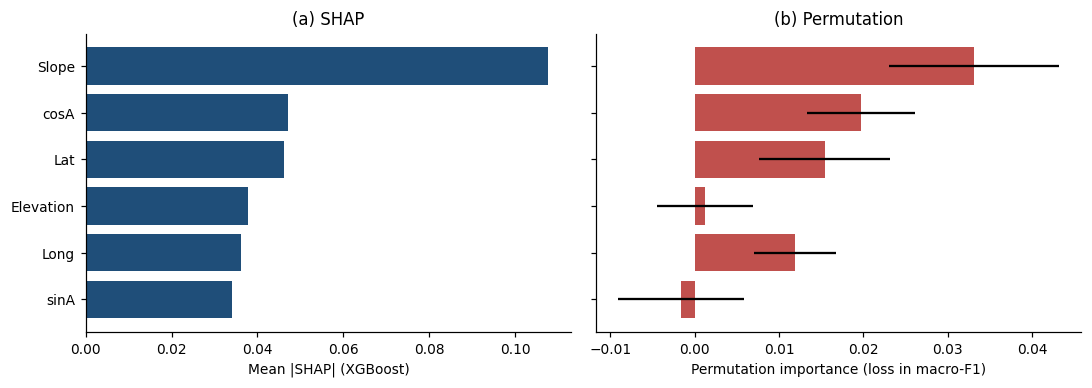

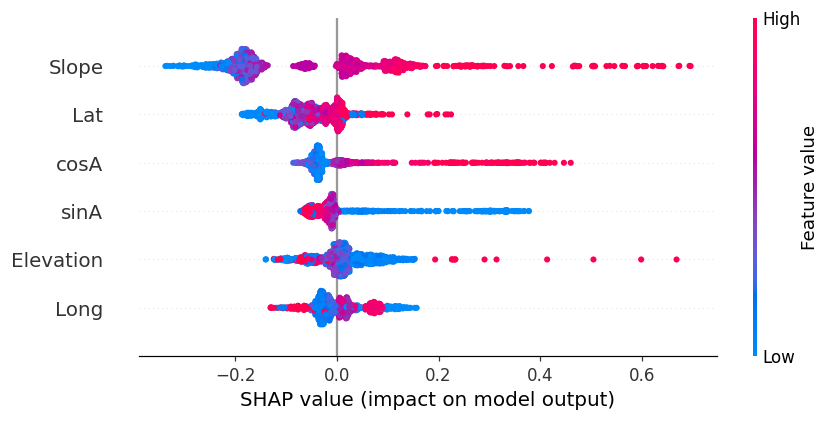


================ FINAL SUMMARY ================
n = 9208 | power law alpha = 2.54, xmin = 5,097 m2 | Moran I (counts) = 0.26 | hotspot cells = 43 | DBSCAN clusters = 24
Logistic Regression  spatial accuracy = 0.385 | macro-F1 = 0.377 | random-split accuracy = 0.376
Random Forest        spatial accuracy = 0.380 | macro-F1 = 0.377 | random-split accuracy = 0.390
XGBoost              spatial accuracy = 0.375 | macro-F1 = 0.372 | random-split accuracy = 0.400
Conclusion: terrain + location explain very little of landslide size; slope is the only consistent predictor.


In [9]:
# Interpretation (SHAP, permutation importance, logistic coefficients) and final summary
import shap
from sklearn.inspection import permutation_importance
xg=E1['XGBoost']['model']; rf=E1['Random Forest']['model']; lr=E1['Logistic Regression']['model']
idx=np.random.default_rng(0).choice(te,1500,replace=False); sv=np.array(shap.TreeExplainer(xg).shap_values(d[F_all].values[idx]))
shap_mean=np.abs(sv).mean(axis=(0,2)) if sv.shape[1]==len(F_all) else (np.abs(sv).mean(axis=(0,1)) if sv.shape[2]==len(F_all) else np.abs(sv).mean(axis=(1,2)))
pi=permutation_importance(rf,d[F_all].values[te],y[te],n_repeats=20,random_state=0,scoring='f1_macro',n_jobs=1)
imp=pd.DataFrame({'Feature':F_all,'Mean |SHAP| (XGBoost)':shap_mean.round(4),'Permutation dF1 (RF)':pi.importances_mean.round(4),'+/- SD':pi.importances_std.round(4)}).sort_values('Mean |SHAP| (XGBoost)',ascending=False)
print('TABLE - Feature importance'); display(imp)
coef=pd.DataFrame(lr[-1].coef_.T,index=F_all,columns=['small','medium','large']).round(3); print('\nLogistic Regression standardised coefficients (per class):'); display(coef)

o=imp.sort_values('Mean |SHAP| (XGBoost)'); fig,ax=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
ax[0].barh(o.Feature,o['Mean |SHAP| (XGBoost)'],color=C[0]); ax[0].set_xlabel('Mean |SHAP| (XGBoost)'); ax[0].set_title('(a) SHAP')
ax[1].barh(o.Feature,o['Permutation dF1 (RF)'],xerr=o['+/- SD'],color=C[1]); ax[1].set_xlabel('Permutation importance (loss in macro-F1)'); ax[1].set_title('(b) Permutation')
plt.tight_layout(); plt.show()
shap.summary_plot(sv[:,:,2] if sv.shape[2]==3 else sv[2],d[F_all].values[idx],feature_names=F_all,show=True)  # SHAP for the 'large' class

print('\n================ FINAL SUMMARY ================')
print(f'n = {len(d)} | power law alpha = {alpha:.2f}, xmin = {xmin:,.0f} m2 | Moran I (counts) = {Ic[0]:.2f} | hotspot cells = {hot.sum()} | DBSCAN clusters = {len(set(lab))-1}')
for k,v in E1.items(): print(f'{k:20s} spatial accuracy = {v["acc"]:.3f} | macro-F1 = {v["f1"]:.3f} | random-split accuracy = {E3[k]["acc"]:.3f}')
print('Conclusion: terrain + location explain very little of landslide size; slope is the only consistent predictor.')